In [1]:
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Visual style configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 11})

In [2]:
import importlib
import helpers
importlib.reload(helpers)
from helpers import (
    get_available_cost_rates, plot_pnl_comparisons, plot_loss_history,
    plot_turnover_vs_cvar, plot_comprehensive_metrics_dashboard,
    plot_cvar_gain_vs_reference, plot_transaction_cost_distributions,
    plot_delta_stability
)


In [3]:
input_dir = "outputs"
output_dir = "graphs"
output_path=Path(output_dir)
if output_path.exists() and output_path.is_dir():
    shutil.rmtree(output_path)
output_path.mkdir(parents=True)

print("[INFO] Scanning for CSV files...")

cost_rates = get_available_cost_rates(input_dir)
if not cost_rates:
        raise FileNotFoundError(f"[ERROR] No files detected at {input_dir}")
else:
    print(f"[INFO] Detected cost rates : {cost_rates}")

[INFO] Scanning for CSV files...
[INFO] Detected cost rates : ['0', '0.001', '0.0025', '0.005', '0.0075', '0.01', '0.015', '0.02', '0.025', '0.03']


[OK] Saved : graphs/plot_pnl_comparison_vs_BS.png


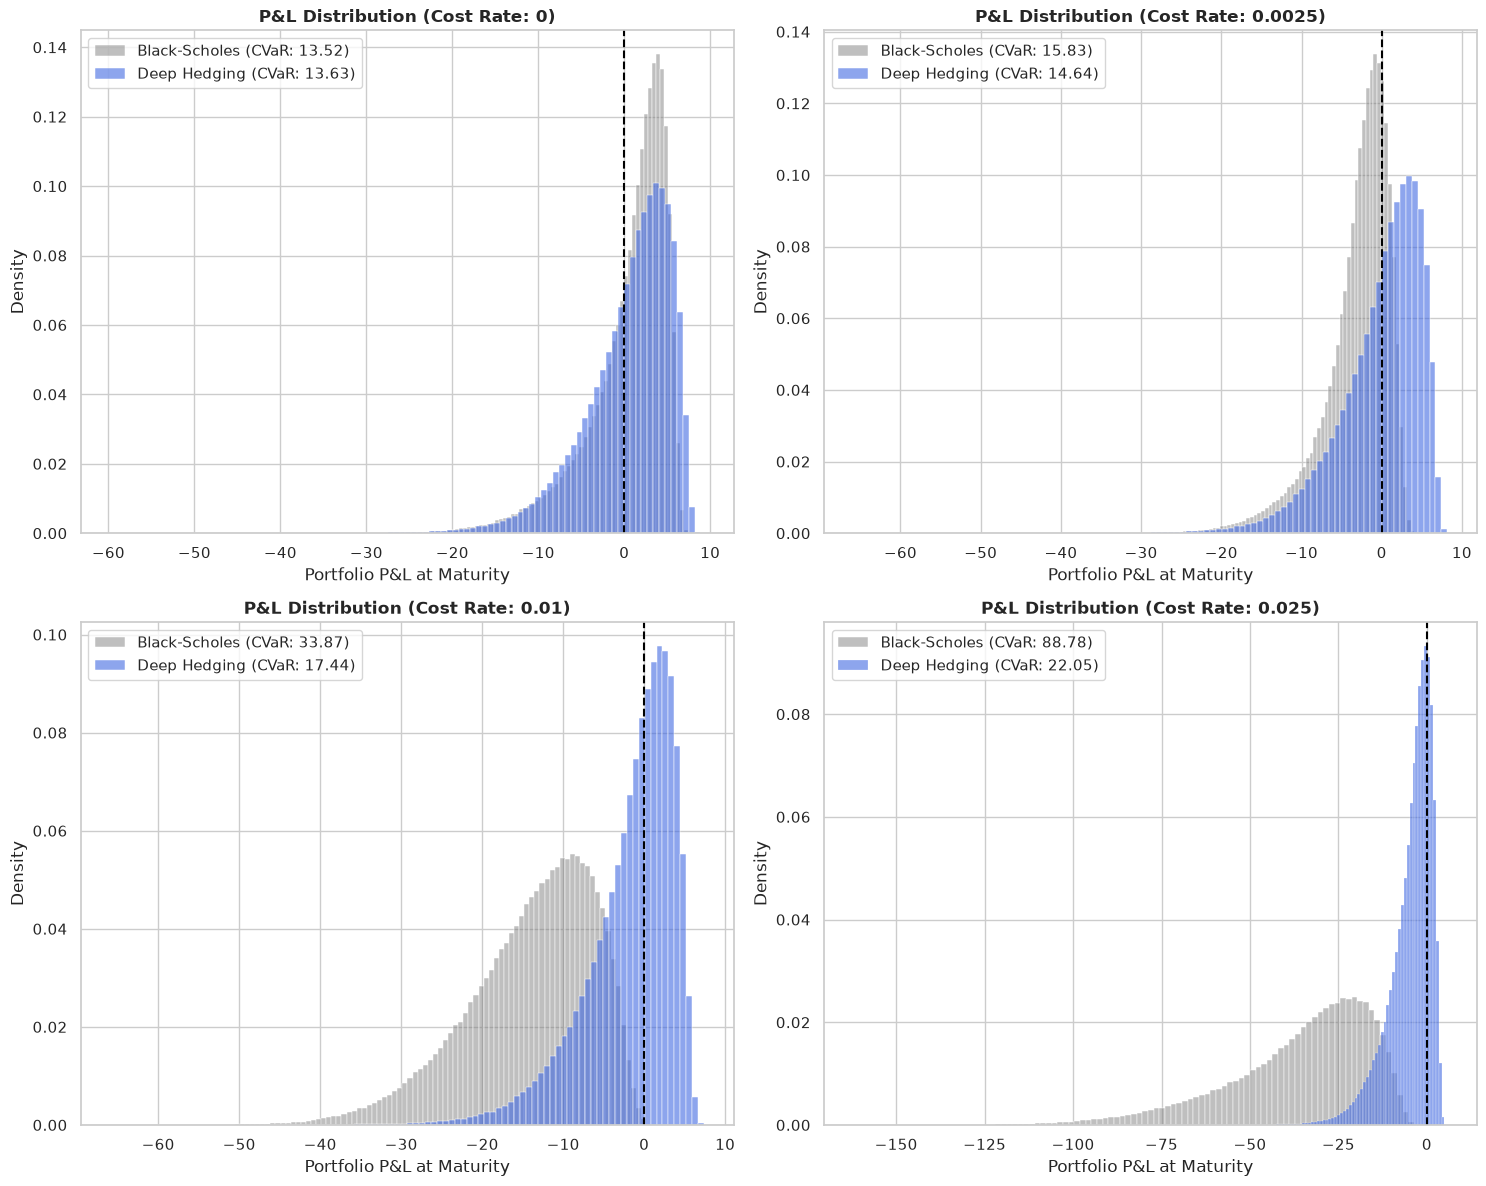

[OK] Saved : graphs/plot_split_loss_history.png


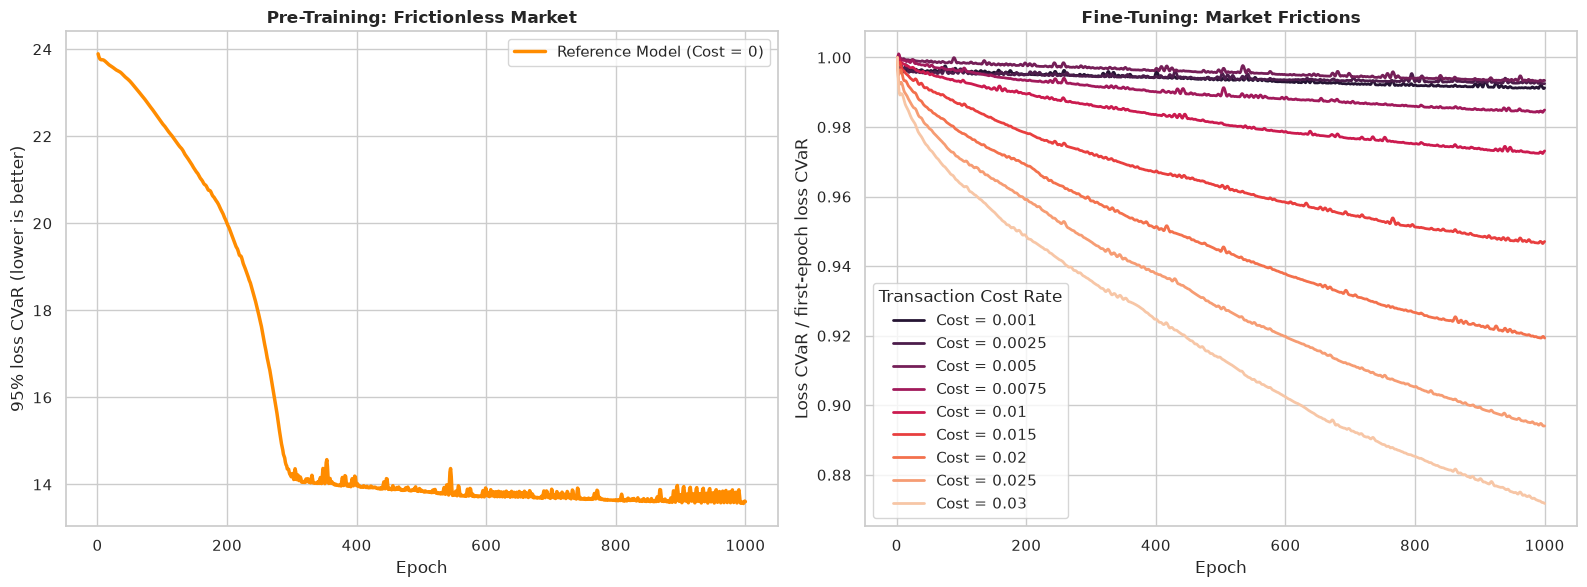

[INFO] Trade-off analysis saved to graphs/turnover_vs_cvar_frontier.png


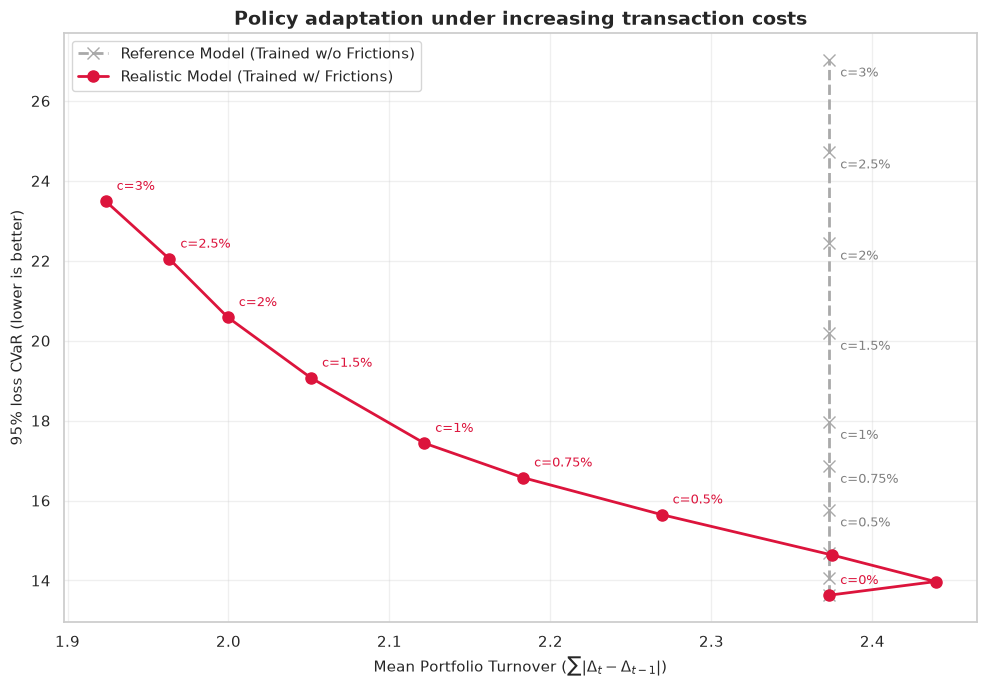

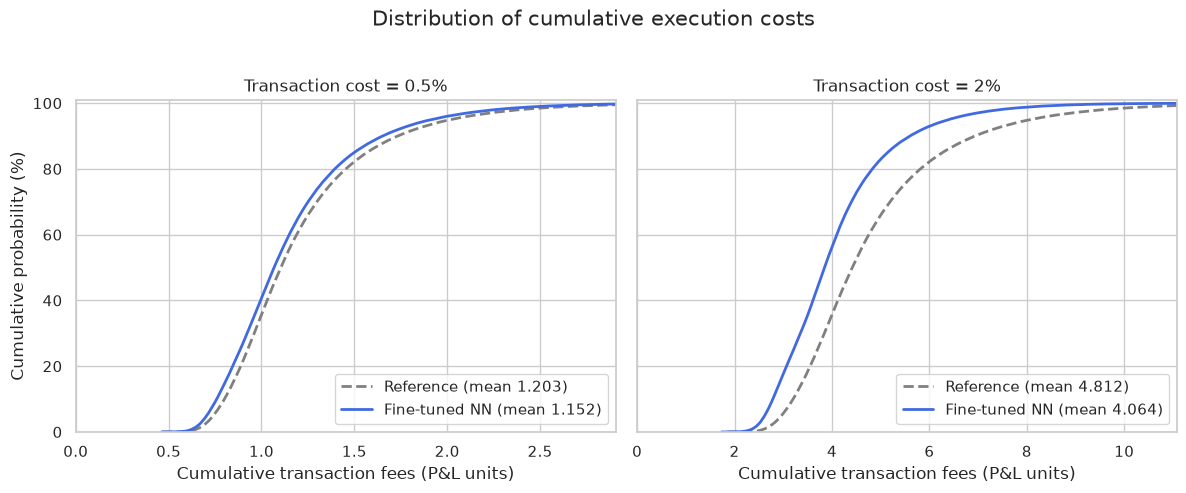

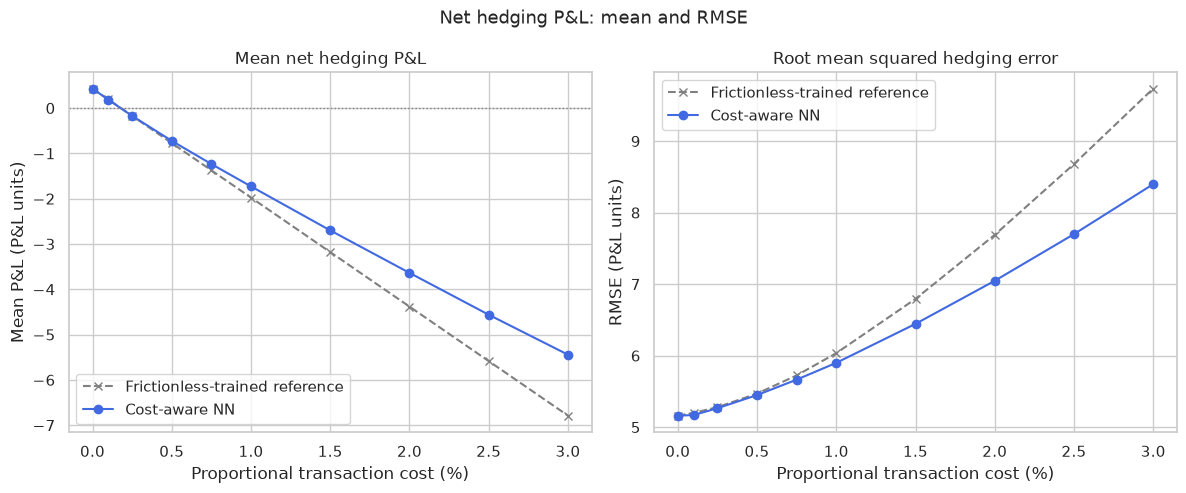

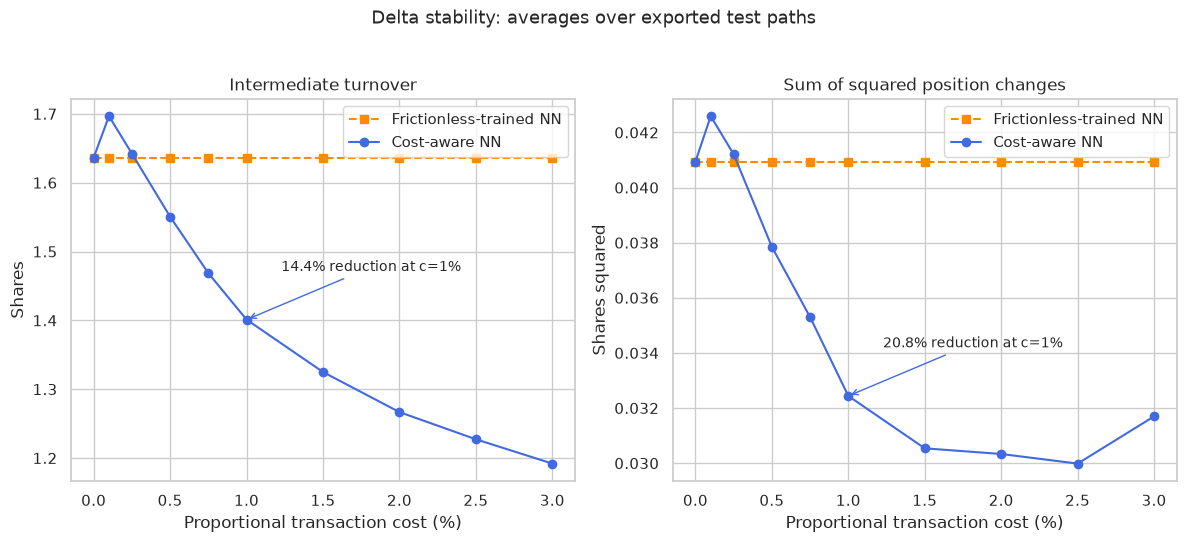

[SUCCESS] All plots have been generated and displayed.


In [5]:
plot_pnl_comparisons([0, 0.0025, 0.01, 0.025], input_dir, output_dir, baseline="BS")
plot_loss_history(cost_rates, input_dir, output_dir)
plot_turnover_vs_cvar(cost_rates, input_dir, output_dir)
# plot_cvar_gain_vs_reference(cost_rates, input_dir, output_dir)
plot_transaction_cost_distributions([0.005, 0.02], input_dir, output_dir)
plot_comprehensive_metrics_dashboard(cost_rates, input_dir, output_dir)
plot_delta_stability(cost_rates, input_dir, output_dir)

print("[SUCCESS] All plots have been generated and displayed.")
plt.close("all")
